In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import Image
from tyssue.topology.base_topology import remove_face
import os


from tyssue import config, Sheet, SheetGeometry, History, EventManager
from tyssue.draw import sheet_view
from tyssue.generation import three_faces_sheet
from tyssue.draw.plt_draw import plot_forces
from tyssue.topology.sheet_topology import resolve_t1s

from tyssue.dynamics import PlanarModel

from tyssue.solvers.viscous import EulerSolver
from tyssue.draw.plt_draw import create_gif


import numpy as np
from tyssue.config.geometry import flat_sheet
from tyssue import Sheet, Monolayer, config, SheetGeometry
import pandas as pd

In [45]:

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. GENERATE HEXAGONAL LATTICE POSITIONS
# ============================================================

def generate_lattice(n_cells):
    """
    Generate compact hexagonal lattice coordinates.

    Parameters
    ----------
    n_cells : int
        Number of hexagonal cells (1-200).

    Returns
    -------
    axial_coords : list
        Axial coordinates of cell centres.
    """

    if not 1 <= n_cells <= 200:
        raise ValueError("n_cells must be between 1 and 200")

    axial_coords = [(0, 0)]

    directions = [
        (1, 0), (1, -1), (0, -1),
        (-1, 0), (-1, 1), (0, 1)
    ]

    ring = 1

    while len(axial_coords) < n_cells:

        q, r = -ring, ring

        for dq, dr in directions:

            for _ in range(ring):

                if len(axial_coords) >= n_cells:
                    break

                axial_coords.append((q, r))

                q += dq
                r += dr

            if len(axial_coords) >= n_cells:
                break

        ring += 1

    return axial_coords


# ============================================================
# 2. CREATE HEXAGONS WITH SHARED VERTICES
# ============================================================

def create_hexagons(axial_coords, side=1.0):
    """
    Construct hexagonal cells with shared vertices.

    Returns
    -------
    vertex_coords : ndarray
        Unique vertex coordinates [x, y, z].
        All z coordinates are zero.
    faces : list
        Vertex indices defining each hexagonal face.
    """

    vertex_coords = []
    faces = []
    vertex_lookup = {}

    angles = np.deg2rad([90, 150, 210, 270, 330, 390])

    for q, r in axial_coords:

        cx = np.sqrt(3) * side * (q + r / 2)
        cy = 1.5 * side * r

        face = []

        for angle in angles:

            x = cx + side * np.cos(angle)
            y = cy + side * np.sin(angle)

            key = (round(x, 8), round(y, 8))

            if key not in vertex_lookup:

                vertex_lookup[key] = len(vertex_coords)

                # Explicitly set z = 0
                vertex_coords.append([x, y, 0.0])

            face.append(vertex_lookup[key])

        faces.append(face)

    return np.asarray(vertex_coords, dtype=float), faces


# ============================================================
# 3. INTRODUCE GEOMETRIC DISORDER
# ============================================================

def introduce_disorder(vertex_coords, disorder=0.04, seed=7):
    """
    Randomly perturb shared vertices in x and y only.

    The z coordinate remains exactly zero.
    """

    rng = np.random.default_rng(seed)

    noisy_coords = np.asarray(
        vertex_coords,
        dtype=float
    ).copy()

    noisy_coords[:, :2] += rng.normal(
        scale=disorder,
        size=noisy_coords[:, :2].shape
    )

    noisy_coords[:, 2] = 0.0

    return noisy_coords


# ============================================================
# 4. CALCULATE POLYGON AREA
# ============================================================

def calculate_polygon_area(coords, face):
    """
    Calculate polygon area using the shoelace formula.
    """

    points = coords[face]

    x = points[:, 0]
    y = points[:, 1]

    return 0.5 * abs(
        np.dot(x, np.roll(y, -1))
        - np.dot(y, np.roll(x, -1))
    )


# ============================================================
# 5. SCALE TISSUE TO TARGET MEAN AREA
# ============================================================

def scale_tissue_to_area(vertex_coords, faces, target_area):
    """
    Scale the complete tissue so that mean cell area
    equals the requested target area.
    """

    if target_area <= 0:
        raise ValueError("target_area must be positive")

    areas = np.array([
        calculate_polygon_area(vertex_coords, face)
        for face in faces
    ])

    if np.any(areas <= 0):
        raise ValueError(
            "Degenerate or inverted cell geometry detected."
        )

    scale = np.sqrt(target_area / areas.mean())

    vertex_coords = vertex_coords.copy()

    vertex_coords[:, :2] *= scale

    # Preserve the planar geometry
    vertex_coords[:, 2] = 0.0

    return vertex_coords


# ============================================================
# 6. IDENTIFY BOUNDARY CELLS
# ============================================================

def identify_boundary_cells(faces):
    """
    Identify boundary cells.

    A cell is a boundary cell if at least one of its
    edges belongs to only one face.
    """

    edge_count = {}

    for face in faces:

        for i in range(len(face)):

            edge = tuple(sorted((
                face[i],
                face[(i + 1) % len(face)]
            )))

            edge_count[edge] = edge_count.get(edge, 0) + 1

    boundary_faces = set()

    for face_id, face in enumerate(faces):

        for i in range(len(face)):

            edge = tuple(sorted((
                face[i],
                face[(i + 1) % len(face)]
            )))

            if edge_count[edge] == 1:

                boundary_faces.add(face_id)
                break

    return boundary_faces


# ============================================================
# 7. PLOT THE TISSUE
# ============================================================

def plot_tissue(
    vertex_coords,
    faces,
    xlim=None,
    ylim=None,
    boundary_color="different",
    boundary_cell_color="blue",
    interior_cell_color="gray",
    show_ids=True,
    figsize=(8, 8)
):
    """
    Plot hexagonal tissue.

    boundary_color:
        'different' -> distinguish boundary and interior cells
        Any matplotlib colour -> uniform edge colour
    """

    coords = np.asarray(vertex_coords)

    boundary_faces = identify_boundary_cells(faces)

    fig, ax = plt.subplots(figsize=figsize)

    for face_id, face in enumerate(faces):

        points = coords[face]

        closed_points = np.vstack([
            points,
            points[0]
        ])

        if boundary_color == "different":

            color = (
                boundary_cell_color
                if face_id in boundary_faces
                else interior_cell_color
            )

        else:
            color = boundary_color

        ax.plot(
            closed_points[:, 0],
            closed_points[:, 1],
            color=color,
            linewidth=1.5,
            marker="o",
            markersize=4
        )

        if show_ids:

            centroid = points[:, :2].mean(axis=0)

            ax.text(
                centroid[0],
                centroid[1],
                str(face_id),
                ha="center",
                va="center"
            )

    ax.set_aspect("equal")

    if xlim is not None:
        ax.set_xlim(xlim)

    if ylim is not None:
        ax.set_ylim(ylim)

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_title(f"Hexagonal tissue: {len(faces)} cells")

    plt.tight_layout()
    plt.show()


# ============================================================
# 8. COMPILE EVERYTHING
# ============================================================

def generate_hexagonal_tissue(
    n_cells=19,
    cell_area=2.0,
    disorder=0.04,
    seed=7,
    xlim=None,
    ylim=None,
    boundary_color="different",
    boundary_cell_color="blue",
    interior_cell_color="gray",
    show_ids=True,
    figsize=(8, 8)
):
    """
    Complete tissue-generation pipeline.

    Returns
    -------
    vertex_coords : list
        Vertex coordinates [x, y, z].
    faces : list
        Vertex indices defining each cell.
    preferred_areas : list
        Preferred area of every cell.
    """

    # 1. Generate cell-centre positions
    axial_coords = generate_lattice(n_cells)

    # 2. Construct hexagons
    vertex_coords, faces = create_hexagons(axial_coords)

    # 3. Introduce disorder
    vertex_coords = introduce_disorder(
        vertex_coords,
        disorder=disorder,
        seed=seed
    )

    # 4. Scale to target mean cell area
    vertex_coords = scale_tissue_to_area(
        vertex_coords,
        faces,
        cell_area
    )

    # 5. Preferred areas
    preferred_areas = [cell_area] * n_cells

    # 6. Plot tissue
    plot_tissue(
        vertex_coords,
        faces,
        xlim=xlim,
        ylim=ylim,
        boundary_color=boundary_color,
        boundary_cell_color=boundary_cell_color,
        interior_cell_color=interior_cell_color,
        show_ids=show_ids,
        figsize=figsize
    )

    # 7. Print information
    areas = np.array([
        calculate_polygon_area(vertex_coords, face)
        for face in faces
    ])

    print("Number of cells:", len(faces))
    print("Number of vertices:", len(vertex_coords))
    print("Mean cell area:", areas.mean())
    print("Minimum cell area:", areas.min())
    print("Maximum cell area:", areas.max())
    print("All z coordinates zero:", np.all(vertex_coords[:, 2] == 0.0))

    return (
        vertex_coords.tolist(),
        faces,
        preferred_areas
    )


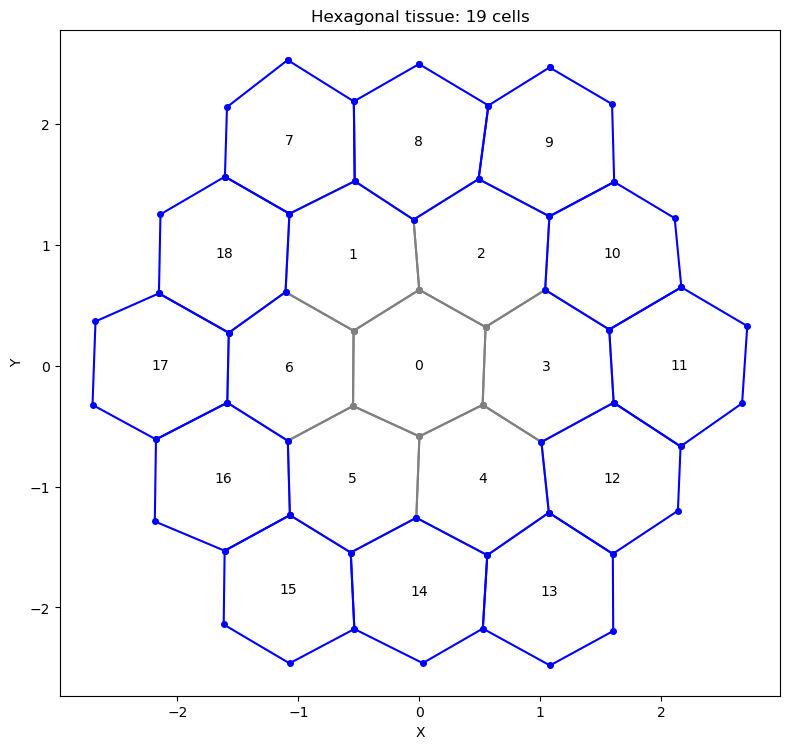

Number of cells: 19
Number of vertices: 54
Mean cell area: 0.9999999999999998
Minimum cell area: 0.9478600152246038
Maximum cell area: 1.0660318533623696
All z coordinates zero: True


In [47]:
vertex_coords, faces, preferred_areas = generate_hexagonal_tissue(
    n_cells=19,
    cell_area=1.0,
    disorder=0.04,
    seed=7,
    boundary_color="different",
    boundary_cell_color="blue",
    interior_cell_color="gray"
)



In [49]:
import numpy as np
import pandas as pd

from tyssue import Sheet, SheetGeometry
from tyssue.generation.utils import make_df
from tyssue.config.geometry import flat_sheet


# ============================================================
# 1. NUMBER OF ELEMENTS
# ============================================================

vertex_coords = np.asarray(vertex_coords, dtype=float)

Nv = len(vertex_coords)
Nc = len(faces)
Ne = sum(len(face) for face in faces)


# ============================================================
# 2. GET TYSSUE SPECIFICATIONS
# ============================================================

specifications = flat_sheet()


# ============================================================
# 3. CREATE DATAFRAMES
# ============================================================

vert_idx = pd.Index(range(Nv), name="vert")
edge_idx = pd.Index(range(Ne), name="edge")
face_idx = pd.Index(range(Nc), name="face")

vert_df = make_df(index=vert_idx, spec=specifications["vert"])
edge_df = make_df(index=edge_idx, spec=specifications["edge"])
face_df = make_df(index=face_idx, spec=specifications["face"])


# ============================================================
# 4. VERTEX COORDINATES (3D)
# ============================================================

vert_df.loc[:, ["x", "y"]] = vertex_coords[:, :2]

# All vertices initially lie in the z = 0 plane
vert_df["z"] = 0.0

vert_df["is_active"] = 1


# ============================================================
# 5. EDGE TOPOLOGY
# ============================================================

edge_rows = []

for face_id, vertices in enumerate(faces):

    for i, srce in enumerate(vertices):

        trgt = vertices[(i + 1) % len(vertices)]

        edge_rows.append({
            "srce": srce,
            "trgt": trgt,
            "face": face_id
        })

edge_df.loc[:, ["srce", "trgt", "face"]] = (
    pd.DataFrame(edge_rows).values
)

edge_df["is_active"] = 1
edge_df["line_tension"] = 0.01


# ============================================================
# 6. FACE PROPERTIES
# ============================================================

face_df["is_alive"] = 1
face_df["prefered_area"] = preferred_areas
face_df["area_elasticity"] = 1.0


# ============================================================
# 7. CONSTRUCT DATASETS
# ============================================================

datasets = {
    "vert": vert_df,
    "edge": edge_df,
    "face": face_df
}


# ============================================================
# 8. CONSTRUCT SHEET USING SHEETGEOMETRY
# ============================================================

sheet = Sheet(
    "disordered_hexagons",
    datasets,
    coords=["x", "y", "z"]
)

geom = SheetGeometry


# ============================================================
# 9. INITIALIZE TOPOLOGY AND GEOMETRY
# ============================================================

sheet.reset_topo()

geom.update_all(sheet)


# ============================================================
# 10. VERIFY MESH
# ============================================================

print("Valid mesh:", sheet.validate())

print("Number of vertices:", len(sheet.vert_df))
print("Number of edges:", len(sheet.edge_df))
print("Number of faces:", len(sheet.face_df))

print("\nSimulation coordinates:", sheet.coords)

print(
    "\nAll vertices initially at z = 0:",
    np.allclose(sheet.vert_df["z"], 0.0)
)

print("\nFace geometry:")

print(
    sheet.face_df[
        ["area", "perimeter", "num_sides"]
    ]
)

print("\nRelative-coordinate columns:")

print([
    c for c in sheet.edge_df.columns
    if c.startswith("r")
])

assert sheet.coords == ["x", "y", "z"]

assert np.allclose(
    sheet.vert_df["z"].to_numpy(),
    0.0
)

assert np.isfinite(
    sheet.face_df["area"].to_numpy()
).all()

print("\n3D SheetGeometry initialization completed.")


Valid mesh: True
Number of vertices: 54
Number of edges: 114
Number of faces: 19

Simulation coordinates: ['x', 'y', 'z']

All vertices initially at z = 0: True

Face geometry:
          area  perimeter  num_sides
face                                
0     0.997343   3.721903          6
1     0.987463   3.701636          6
2     0.983696   3.695291          6
3     0.989799   3.708087          6
4     0.986188   3.700559          6
5     0.989340   3.706941          6
6     0.947860   3.626769          6
7     1.001160   3.732388          6
8     1.025298   3.777086          6
9     0.994612   3.719938          6
10    0.978776   3.686044          6
11    1.066032   3.851118          6
12    1.002214   3.734986          6
13    0.996465   3.721425          6
14    0.997432   3.722109          6
15    0.979378   3.685857          6
16    1.032489   3.788248          6
17    1.019102   3.764932          6
18    1.025352   3.774731          6

Relative-coordinate columns:
['rx', 'ry', 'rz

C:\Users\Aryan\AppData\Local\Temp\ipykernel_27468\3416649278.py:124: DeprecationWarning: `alltrue` is deprecated as of NumPy 1.25.0, and will be removed in NumPy 2.0. Please use `all` instead.
  print("Valid mesh:", sheet.validate())


In [51]:
################# cell individual functions ##########################


# axial_coords = generate_lattice(37)

# vertex_coords, faces = create_hexagons(axial_coords)

# vertex_coords = introduce_disorder(
#     vertex_coords,
#     disorder=0.04
# )

# vertex_coords = scale_tissue_to_area(
#     vertex_coords,
#     faces,
#     target_area=2.0
# )

# boundary_faces = identify_boundary_cells(faces)

# plot_tissue(
#     vertex_coords,
#     faces,
#     boundary_color="different"
# )

Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261119_194611_103777.png


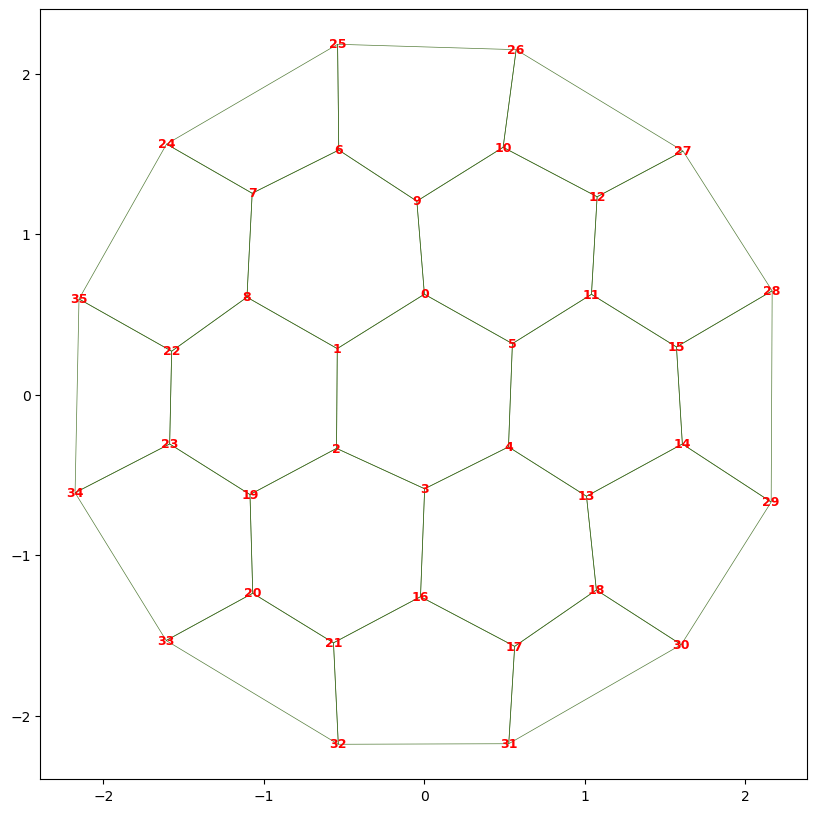

In [53]:
########## boundary face inactive ####################

# sheet.get_opposite()
# free_edges = sheet.edge_df[sheet.edge_df["opposite"] == -1]
# boundary_verts = np.unique(
#     np.r_[free_edges["srce"].to_numpy(), free_edges["trgt"].to_numpy()]
# )
# sheet.vert_df.loc[boundary_verts, "is_active"] = 0

# print(sheet.vert_df["is_active"].value_counts())
#######################################################
# sheet.get_opposite()

# free_edges = sheet.edge_df[sheet.edge_df["opposite"] == -1]
# boundary_verts = np.unique(
#     np.r_[free_edges["srce"].to_numpy(), free_edges["trgt"].to_numpy()]
# )
# # Keep the boundary cells as active cells
# boundary_faces = free_edges["face"].unique()
# sheet.face_df.loc[boundary_faces, "is_alive"] = 1

# # Fix the outline while allowing interior vertices to relax
# sheet.vert_df.loc[boundary_verts, "is_active"] = 0

# def update_boundary_activity(sheet):
#     sheet.get_opposite()
#     free_edges = sheet.edge_df[sheet.edge_df["opposite"] == -1]
#     boundary_verts = np.unique(
#         np.r_[free_edges["srce"].to_numpy(), free_edges["trgt"].to_numpy()]
#     )

#     sheet.vert_df["is_active"] = 1
#     sheet.vert_df.loc[boundary_verts, "is_active"] = 0

sheet.sanitize(trim_borders=True, order_edges=True)
geom.update_all(sheet)
# update_boundary_activity(sheet)


fig, ax = sheet_view(sheet)

# Plot vertex IDs
for vertex_id, vertex in sheet.vert_df.iterrows():

    ax.text(
        vertex["x"],
        vertex["y"],
        str(vertex_id),
        color="red",
        fontsize=9,
        ha="center",
        va="center",
        fontweight="bold"
    )

fig.set_size_inches(10, 10)
ax.set_aspect("equal")
plt.show()

fig.set_size_inches(10, 10)
ax.set_aspect('equal')


# fig, ax = sheet_view(sheet)

# fig.set_size_inches(10, 10)
# ax.set_aspect('equal')



In [54]:
vertices = sheet.vert_df  # bu this we can get the vertices coords and store it in vertices
display(vertices)

print(sheet.vert_df[["x", "y"]]);
print(sheet.face_df[["area", "num_sides"]])
sheet.face_df

,x,y,z,is_active,rho,height,basal_shift
vert,,,,,,,
0,0.000030,0.626424,0.0,1,0.0,-4.0,4.0
1,-0.542881,0.287462,0.0,1,0.0,-4.0,4.0
2,-0.547351,-0.334068,0.0,1,0.0,-4.0,4.0
3,0.001489,-0.585842,0.0,1,0.0,-4.0,4.0
4,0.523906,-0.324877,0.0,1,0.0,-4.0,4.0
5,0.548222,0.318350,0.0,1,0.0,-4.0,4.0
6,-0.533483,1.524528,0.0,1,0.0,-4.0,4.0
7,-1.072911,1.255271,0.0,1,0.0,-4.0,4.0
8,-1.105471,0.607696,0.0,1,0.0,-4.0,4.0


             x         y
vert                    
0     0.000030  0.626424
1    -0.542881  0.287462
2    -0.547351 -0.334068
3     0.001489 -0.585842
4     0.523906 -0.324877
5     0.548222  0.318350
6    -0.533483  1.524528
7    -1.072911  1.255271
8    -1.105471  0.607696
9    -0.047076  1.206124
10    0.490490  1.541747
11    1.040803  0.625744
12    1.076068  1.233426
13    1.009869 -0.632366
14    1.607079 -0.306708
15    1.570392  0.297684
16   -0.024229 -1.258082
17    0.562362 -1.567563
18    1.071381 -1.216156
19   -1.086637 -0.621793
20   -1.069451 -1.236475
21   -0.566427 -1.545682
22   -1.574634  0.271205
23   -1.587000 -0.306558
24   -1.606435  1.561847
25   -0.540768  2.183505
26    0.571713  2.149865
27    1.611431  1.518172
28    2.166627  0.647384
29    2.160391 -0.668362
30    1.600177 -1.556694
31    0.525495 -2.174114
32   -0.536378 -2.177578
33   -1.608877 -1.531018
34   -2.176337 -0.610443
35   -2.151912  0.596744
          area  num_sides
face                    

,x,y,z,num_sides,area,perimeter,is_alive,id,prefered_area,area_elasticity,height,rho,vol
face,,,,,,,,,,,,,
0,-0.002764,-0.002092,0.0,6,0.997343,3.721903,1,0,1.0,1.0,-4.0,0.0,-3.989372
1,-0.550299,0.917917,0.0,6,0.987463,3.701636,1,0,1.0,1.0,-4.0,0.0,-3.949852
2,0.518090,0.925302,0.0,6,0.983696,3.695291,1,0,1.0,1.0,-4.0,0.0,-3.934786
3,1.050045,-0.003695,0.0,6,0.989799,3.708087,1,0,1.0,1.0,-4.0,0.0,-3.959198
4,0.524130,-0.930814,0.0,6,0.986188,3.700559,1,0,1.0,1.0,-4.0,0.0,-3.944751
5,-0.548768,-0.930324,0.0,6,0.989340,3.706941,1,0,1.0,1.0,-4.0,0.0,-3.957361
6,-1.073996,-0.016009,0.0,6,0.947860,3.626769,1,0,1.0,1.0,-4.0,0.0,-3.791440
7,-0.938399,1.631288,0.0,4,0.507904,3.110981,1,0,1.0,1.0,-4.0,0.0,-2.031618
8,-0.011825,1.721154,0.0,5,0.844282,3.600613,1,0,1.0,1.0,-4.0,0.0,-3.377127


In [55]:
from tyssue.draw import (sheet_view, highlight_faces, create_gif, browse_history)


from tyssue.dynamics import effectors, model_factory

area_model = model_factory([
    effectors.FaceAreaElasticity,
    effectors.LineTension
    # effectors.PerimeterElasticity
])

sheet.update_specs(area_model.specs, reset=True)


# Area energy parameters
### Pandas warns because chained indexing (["column"].iloc[]) may modify a temporary view rather than the original DataFrame. ###
# sheet.face_df["area_elasticity"].iloc[0] = 1.0
# sheet.face_df["area_elasticity"].iloc[0] = 1.0

# sheet.face_df["prefered_area"].iloc[0] = 8.0
# sheet.face_df["prefered_area"].iloc[1] = 8.0

# Area elasticity for both faces
for cell_id in range(0,19):

    if cell_id == 0: 
        sheet.face_df.loc[cell_id, "area_elasticity"] = 1.0

    else:
        sheet.face_df.loc[cell_id, "area_elasticity"] = 1.0

# for cell_id in range(8,19):
#     sheet.face_df.loc[cell_id, "area_elasticity"] = 1.0

# Preferred area for both faces


for cell_id in range(0,19):
    sheet.face_df.loc[cell_id, "prefered_area"] =  4.0
    # np.random.randint(3, 7, size=len(sheet.face_df))
# sheet.face_df.loc[0, "prefered_area"] = 4
# sheet.face_df.loc[1, "prefered_area"] = 4
# sheet.face_df.loc[2, "prefered_area"] = 4
# sheet.face_df.loc[3, "prefered_area"] = 4
# sheet.face_df.loc[4, "prefered_area"] = 4
# sheet.face_df.loc[5, "prefered_area"] = 4
# sheet.face_df.loc[6, "prefered_area"] = 4
# sheet.face_df.loc[7, "prefered_area"] = 4
# sheet.face_df.loc[8, "prefered_area"] = 4
# sheet.face_df.loc[9, "prefered_area"] = 4
# sheet.face_df.loc[10, "prefered_area"] = 4
# sheet.face_df.loc[11, "prefered_area"] = 4
# sheet.face_df.loc[12, "prefered_area"] = 4
# sheet.face_df.loc[13, "prefered_area"] = 4
# sheet.face_df.loc[14, "prefered_area"] = 4
# sheet.face_df.loc[15, "prefered_area"] = 4
# sheet.face_df.loc[16, "prefered_area"] = 4
# sheet.face_df.loc[17, "prefered_area"] = 4
# sheet.face_df.loc[18, "prefered_area"] = 4
# target_area = sheet.face_df["prefered_area"].iloc[0]

# line tension affector value
sheet.edge_df["line_tension"] = 0.5

# Perimeter energy parameters
# sheet.face_df["perimeter_elasticity"] = 1.0
# sheet.face_df["prefered_perimeter"] = 6 * np.sqrt(4 * target_area/ (3 * np.sqrt(3)))
# sheet.face_df["prefered_perimeter"] = 6.0 # this gives a regular hexagon shape 


geom.update_all(sheet)
# print(target_area)

sheet.get_opposite()
boundary_faces = sheet.edge_df.loc[sheet.edge_df["opposite"] == -1, "face"].unique()
print(boundary_faces)

# Increase their area stiffness fivefold
# sheet.face_df["base_area_elasticity"] = sheet.face_df["area_elasticity"].copy()
# sheet.face_df.loc[boundary_faces, "area_elasticity"] = (5.0 * sheet.face_df.loc[boundary_faces, "base_area_elasticity"])


# sheet.face_df["prefered_perimeter"] = sheet.face_df["perimeter"]
# sheet.face_df["base_perimeter_elasticity"] = sheet.face_df["perimeter_elasticity"]
# sheet.face_df.loc[boundary_faces, "perimeter_elasticity"] *= 5.0
sheet.face_df
sheet.edge_df[["line_tension"]]


Reseting column is_alive of the face dataset with new specs
Reseting column area of the face dataset with new specs
Reseting column area_elasticity of the face dataset with new specs
Reseting column prefered_area of the face dataset with new specs
Reseting column sub_area of the edge dataset with new specs
Reseting column is_active of the edge dataset with new specs
Reseting column line_tension of the edge dataset with new specs


[ 7  8  9 10 11 12 13 14 15 16 17 18]


,line_tension
edge,
0,0.5
1,0.5
2,0.5
3,0.5
4,0.5
...,...
91,0.5
92,0.5
93,0.5


In [57]:
import numpy as np

grad_E = area_model.compute_gradient(sheet)

grad_E["magnitude"] = np.sqrt(grad_E["gx"]**2 + grad_E["gy"]**2 + grad_E["gz"]**2)

print(grad_E[["gx", "gy", "gz", "magnitude"]])

area_model.specs

            gx        gy   gz  magnitude
srce                                    
0     0.030256  0.017912  0.0   0.035161
1    -0.009386 -0.020504  0.0   0.022550
2    -0.039271 -0.047047  0.0   0.061283
3     0.027788  0.062565  0.0   0.068458
4     0.009212 -0.012739  0.0   0.015721
5     0.034182 -0.004873  0.0   0.034528
6    -0.118047  0.160122  0.0   0.198933
7    -0.043837  0.250594  0.0   0.254399
8    -0.119078  0.052632  0.0   0.130191
9    -0.045792  0.032096  0.0   0.055920
10    0.067839  0.165316  0.0   0.178694
11    0.035476  0.066444  0.0   0.075321
12    0.097788  0.258416  0.0   0.276300
13   -0.012831 -0.044406  0.0   0.046222
14    0.260058  0.070178  0.0   0.269361
15    0.170872 -0.057797  0.0   0.180382
16   -0.019649 -0.111735  0.0   0.113450
17    0.232817 -0.190989  0.0   0.301132
18    0.103065 -0.161466  0.0   0.191555
19   -0.102988 -0.020304  0.0   0.104970
20   -0.046727 -0.220232  0.0   0.225134
21   -0.210400 -0.167259  0.0   0.268782
22   -0.153487 -

{'cell': {},
 'face': {'is_alive': 1,
  'area': 1.0,
  'area_elasticity': 1.0,
  'prefered_area': 1.0},
 'edge': {'sub_area': 0.16666666666666666,
  'is_active': 1,
  'line_tension': 1.0},
 'vert': {},
 'settings': {'nrj_norm_factor': 1.0}}

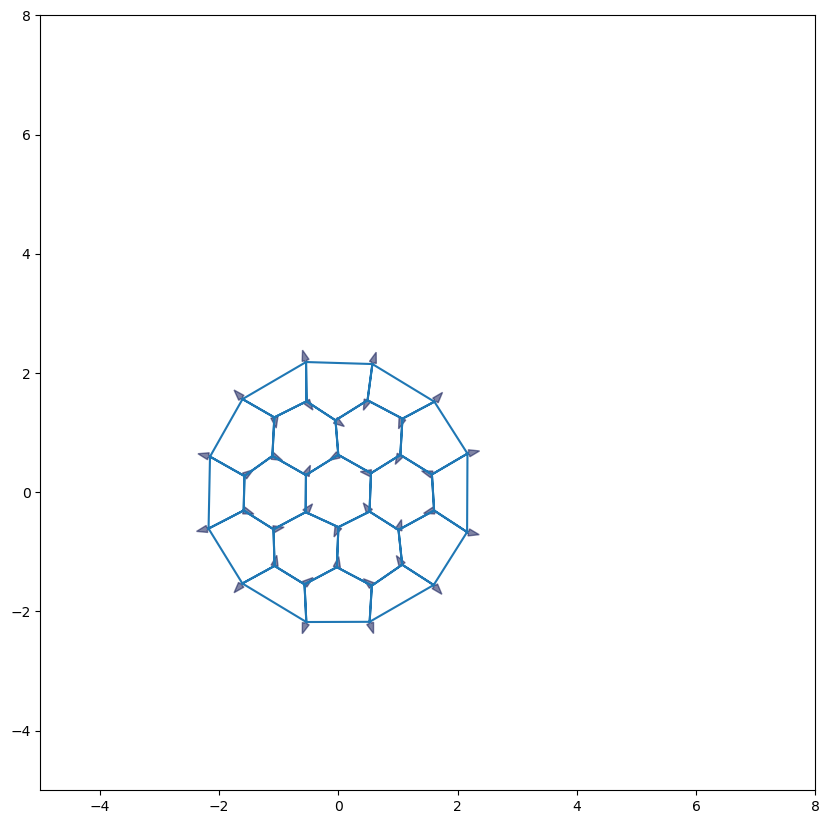

In [61]:
from tyssue.draw.plt_draw import plot_forces


fig, ax = plot_forces(sheet, geom, area_model, ['x', 'y'], scaling=0.009)
ax.set_xlim(-5, 8)
ax.set_ylim(-5, 8)

fig.set_size_inches(10, 12)

Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261119_194613_800732.png


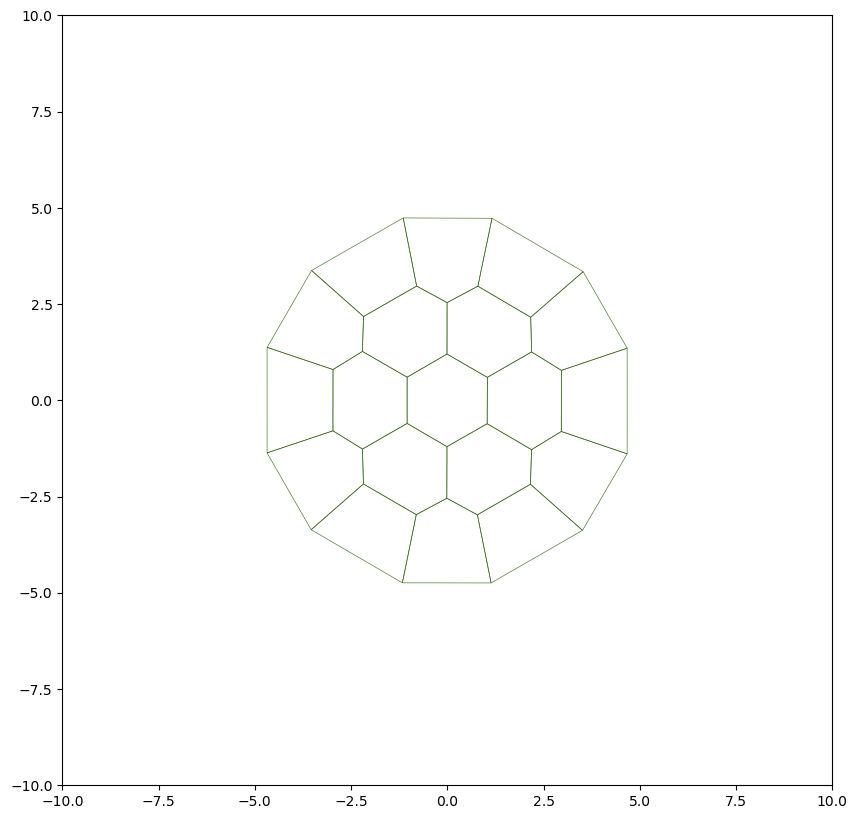

In [62]:
from tyssue.solvers import QSSolver
from pprint import pprint

import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
# Check the tissue is at its equilibrium
solver = QSSolver()
res = solver.find_energy_min(sheet, geom, area_model)
# Visualisation of the tissue
fig, ax = sheet_view(sheet)

ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
fig.set_size_inches(10, 10)

In [64]:
print(sheet.face_df[["area", "num_sides"]])

          area  num_sides
face                     
0     3.754326          6
1     3.750683          6
2     3.750446          6
3     3.749114          6
4     3.750000          6
5     3.750416          6
6     3.748558          6
7     3.704086          4
8     3.783313          5
9     3.703999          4
10    3.783109          5
11    3.704232          4
12    3.783891          5
13    3.705197          4
14    3.784250          5
15    3.704870          4
16    3.784749          5
17    3.706608          4
18    3.784274          5


In [66]:
from tyssue.topology.sheet_topology import cell_division

sheet.face_df["generation"] = 0


def division(sheet, manager, cell_uid=0, crit_area=2.0,growth_rate=0.5, dt=1.0, generations=8):
    """Grow a cell until it crosses the area threshold, then divide it.

    cell_uid is a persistent ID stored in face_df, so queued events remain
    attached to the intended cell when Tyssue reorders face indices.
    """
    if generations <= 0:
        return

    matches = sheet.face_df.index[sheet.face_df["event_id"] == cell_uid]
    if len(matches) == 0:
        return  # The queued cell no longer exists.

    cell_id = matches[0]

    if sheet.face_df.loc[cell_id, "area"] > crit_area:
        # Save the parent's target area and generation before division.
        A0 = float(sheet.face_df.loc[cell_id, "prefered_area"])
        parent_generation = int(sheet.face_df.loc[cell_id, "generation"])
        
        daughter = cell_division(sheet, cell_id, geom)
        
        # Split the parent's preferred area between the two resulting cells.
        sheet.face_df.loc[[cell_id, daughter], "prefered_area"] = A0 / 2

        daughter_uid = int(sheet.settings["next_event_id"])
        sheet.settings["next_event_id"] = daughter_uid + 1
        sheet.face_df.loc[daughter, "event_id"] = daughter_uid
        sheet.face_df.loc[daughter, "generation"] = parent_generation + 1

        sheet.reset_index(order=True)
        sheet.reset_topo()
        geom.update_all(sheet)

        manager.append(
            division,
            cell_uid=cell_uid,
            crit_area=crit_area,
            growth_rate=growth_rate,
            dt=dt,
            generations=generations - 1,
        )
        manager.append(
            division,
            cell_uid=daughter_uid,
            crit_area=crit_area,
            growth_rate=growth_rate,
            dt=dt,
            generations=generations - 1,
        )
    else:
        sheet.face_df.loc[cell_id, "prefered_area"] *= (1 + dt * growth_rate)
        manager.append(
            division,
            cell_uid=cell_uid,
            crit_area=crit_area,
            growth_rate=growth_rate,
            dt=dt,
            generations=generations,
        )


In [69]:
# from IPython.display import clear_output, display
# import matplotlib.pyplot as plt
# from tyssue.draw import sheet_view

# # ============================================================
# # 1. DRAWING SPECIFICATIONS
# # ============================================================

# draw_specs = {
#     "edge": {
#         "color": "black"
#     },
#     "face": {
#         "visible": True,
#         "color": lambda sheet: sheet.face_df["generation"],
#         "color_range": (0, 5),
#         "colormap": "Blues"
#     }
# }


# # ============================================================
# # 2. INITIALIZE SIMULATION
# # ============================================================

# sheet.face_df["generation"] = 0

# t = 0
# stop = 30

# history = History(sheet)

# manager = EventManager("face")

# # Schedule cell division
# manager.append(
#     division_event,
#     geom=geom,
#     cell_id=0,
#     crit_area=2.0,
#     growth_rate=0.6,
#     dt_growth=1.0,
#     generations=5
# )

# manager.update()


# # ============================================================
# # 3. SIMULATION LOOP
# # ============================================================

# while manager.current and t < stop:

#     # Execute division events
#     manager.execute(sheet)

#     # Update topology and geometry
#     sheet.reset_index(order=False)
#     geom.update_all(sheet)

#     # Mechanical relaxation
#     res = solver.find_energy_min(sheet, geom, area_model)

#     # Record history
#     history.record()

#     # Plot current tissue
#     clear_output(wait=True)

#     fig, ax = sheet_view(
#         sheet,
#         mode="2D",
#         **draw_specs
#     )

#     ax.set_title(f"Step {t}")
#     ax.set_aspect("equal")

#     display(fig)
#     plt.close(fig)

#     t += 1

#     manager.update()

In [71]:
# from tyssue.topology.sheet_topology import cell_division

# sheet.face_df["generation"] = 0


# def division(sheet, manager, cell_id=0, crit_area=4.0,
#              growth_rate=0.1, dt=1.0, generations=5):

#     if generations <= 0:
#         return

#     if cell_id not in sheet.face_df.index:
#         print(f"Cell {cell_id} not found")
#         return

#     if sheet.face_df.loc[cell_id, "area"] > crit_area:

#         parent_generation = sheet.face_df.loc[cell_id, "generation"]

#         daughter = cell_division(sheet, cell_id, geom, orientation='vertical')

#         # Recalculate topology and geometry
#         sheet.reset_index(order=True)
#         geom.update_all(sheet)

#         # Check whether IDs still exist
#         print("Division occurred")
#         print("Parent:", cell_id)
#         print("Daughter returned:", daughter)
#         print("Available cells:", sheet.face_df.index.tolist())

#         # Assign daughter generation only if ID is valid
#         if daughter in sheet.face_df.index:
#             sheet.face_df.loc[daughter, "generation"] = parent_generation + 1

#         # Schedule parent for another generation
#         if cell_id in sheet.face_df.index:
#             manager.append(
#                 division,
#                 cell_id=cell_id,
#                 crit_area=crit_area,
#                 growth_rate=growth_rate,
#                 dt=dt,
#                 generations=generations - 1
#             )

#         # Schedule daughter for another generation
#         if daughter in sheet.face_df.index:
#             manager.append(
#                 division,
#                 cell_id=daughter,
#                 crit_area=crit_area,
#                 growth_rate=growth_rate,
#                 dt=dt,
#                 generations=generations - 1
#             )

#     else:

#         sheet.face_df.loc[cell_id, "prefered_area"] *= (
#             1 + dt * growth_rate
#         )

#         manager.append(
#             division,
#             cell_id=cell_id,
#             crit_area=crit_area,
#             growth_rate=growth_rate,
#             dt=dt,
#             generations=generations
#         )

In [73]:
initial_sheet = sheet.copy()

Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261119_194839_517678.png
Saved complete stress plot: C:\Users\Aryan\Tyssue_outputs\stress_step_0020.png


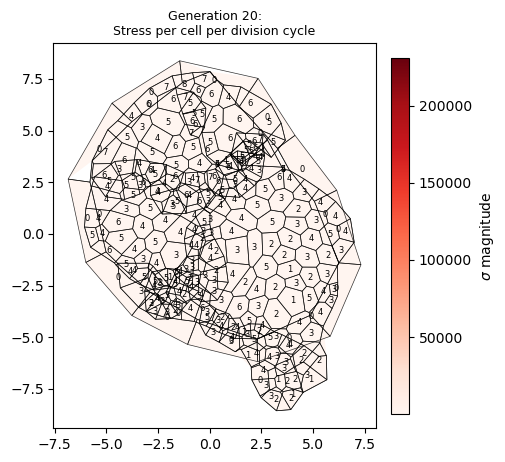

In [75]:
from IPython.display import clear_output, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from tyssue.draw import sheet_view
from tyssue.topology.sheet_topology import type1_transition
from IPython.display import Markdown, display

def add_face_stress(sheet):
    """Add a local energy-based 2D stress magnitude to each face."""

    # get the dataframes of face and edges 
    faces = sheet.face_df
    edges = sheet.edge_df
    
    area = faces["area"].to_numpy(dtype=float) # convert area values to a numpy array float
    preferred_area = faces["prefered_area"].to_numpy(dtype=float) # same for prefered area numpy array
    area_elasticity = faces["area_elasticity"].to_numpy(dtype=float) # and for area elasticity numpy array
   
    alive = (faces["is_alive"].to_numpy(dtype=float) if "is_alive" in faces else np.ones(len(faces))) # take all the active cells

    #*******************#
    area_stress = area_elasticity * (area - preferred_area) * alive # area contribution to stress tensor 
    #******************#

    geom.update_all(sheet)
    
    length = edges["length"].to_numpy(dtype=float) # convert edge length to a float numpy array
    
    dx = edges["dx"].to_numpy(dtype=float) #numpy array
    dy = edges["dy"].to_numpy(dtype=float) #numpy array

    safe_length = np.maximum(length, 1e-12)  # avoid edges with zero length
    ux, uy = dx / safe_length, dy / safe_length  # unit direction vector along the edge
    active = (
        edges["is_active"].to_numpy(dtype=float)
        if "is_active" in edges else np.ones(len(edges))    # acts like a binary switch. takes into account which edges to consider for the calculation. if edge is alive then ae = 1 else 0 
    )
    tension = edges["line_tension"].to_numpy(dtype=float)

    # Tyssue stores directed half-edges; its line-tension energy uses /2.
    weight = 0.5 * tension * active * length
    parts = pd.DataFrame({
        "face": edges["face"].to_numpy(),
        "xx": weight * ux * ux,
        "xy": weight * ux * uy,
        "yy": weight * uy * uy,
    })
    line = (
        parts.groupby("face")[["xx", "xy", "yy"]]
        .sum()
        .reindex(faces.index, fill_value=0.0)
    )

    safe_area = np.maximum(area, 1e-12)

    # main stress tensor calculation 
    sxx = area_stress + line["xx"].to_numpy() / safe_area
    sxy = line["xy"].to_numpy() / safe_area
    syy = area_stress + line["yy"].to_numpy() / safe_area

    #########
    # The Frobenius norm is a way of measuring the “size” of a matrix, generalizing the idea of vector length (Euclidean norm) from vectors to matrices.
    # Square every entry of the matrix, sum all these squares, and take the square root
    #########
    
    faces["stress_magnitude"] = np.sqrt(sxx**2 + 2 * sxy**2 + syy**2)  # final value to plot STRESS MAGNITUDE . [Forbenius Norm] 


def plot_face_stress(sheet, step, color_range=None):
    values = sheet.face_df["stress_magnitude"]
    if color_range is None:
        vmin, vmax = float(values.min()), float(values.max())
        if np.isclose(vmin, vmax):
            vmax = vmin + 1e-12
    else:
        vmin, vmax = color_range

    # Use the same red palette and limits for faces and the colorbar.
    specs = {
        "edge": {"color": "black"},
        "face": {
            "visible": True,
            "color": values,
            "colormap": "Reds",
            "color_range": (vmin, vmax),
        },
    }

    fig, ax = sheet_view(sheet, mode="2D", **specs)

    # Add the colorbar directly to Matplotlib so it is always visible.
    from matplotlib.colors import Normalize
    from matplotlib.cm import ScalarMappable

    
    color_map = plt.get_cmap("Reds")
    mappable = ScalarMappable(
        norm=Normalize(vmin=vmin, vmax=vmax), cmap=color_map
    )
    mappable.set_array([])
    fig.colorbar(
        mappable, ax=ax, fraction=0.046, pad=0.04,
        label=r"$\sigma$ magnitude"
    )

    ax.set_title(f"Generation {step}:\nStress per cell per division cycle", fontsize=9)
    if {"x", "y", "generation"}.issubset(sheet.face_df.columns):
        for _, face in sheet.face_df.iterrows():
            ax.text(
                face["x"], face["y"], str(int(face["generation"])),
                ha="center", va="center", fontsize=6, color="black"
            )
    return fig, ax


# Start from the same initialized tissue saved in cell 15.
sheet = initial_sheet.copy()
sheet.face_df["generation"] = 0
sheet.face_df["event_id"] = np.arange(sheet.Nf, dtype=int)
sheet.settings["next_event_id"] = int(sheet.Nf)

# Keep this T1 threshold fixed during the run.
sheet.settings["threshold_length"] = 0.05 * sheet.edge_df["length"].median()

# Set to a fixed pair, e.g. (0, 2), to compare colors across steps.
# None automatically scales the colors separately for each displayed step.
STRESS_COLOR_RANGE = None

# Save each fully annotated frame (plot + generation numbers + stress bar).
PLOT_DIR = Path.home() / "Tyssue_outputs"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

t1_event_log = []
stress_log = []
history = History(sheet)
manager = EventManager("face")
manager.append(division, cell_uid=0, generations=8)
manager.update()

t = 0
stop = 500

while manager.current and t < stop:
    t1_this_step = 0

    manager.execute(sheet)
    sheet.reset_index(order=False)
    geom.update_all(sheet)

    # Relax after growth or division.
    res = solver.find_energy_min(sheet, geom, area_model)

    # Resolve short internal edges only; free boundary edges are excluded.
    # for _ in range(100):
    #     sheet.get_opposite()
    #     candidates = sheet.edge_df[
    #         (sheet.edge_df["length"] < sheet.settings["threshold_length"])
    #         & (sheet.edge_df["opposite"] != -1)
    #     ]
    #     if candidates.empty:
    #         break

    #     edge_id = candidates["length"].idxmin()

    #     opposite_id = int(sheet.edge_df.loc[edge_id, "opposite"])
    #     face_a = int(sheet.edge_df.loc[edge_id, "face"])
    #     face_b = int(sheet.edge_df.loc[opposite_id, "face"])
        
    #     gen_a = int(sheet.face_df.loc[face_a, "generation"])
    #     gen_b = int(sheet.face_df.loc[face_b, "generation"])
        
    #     t1_event_log.append({
    #         "step": t,
    #         "n_cells": int(sheet.Nf),
    #         "generation_a": gen_a,
    #         "generation_b": gen_b,
    #         # Count this event once, under the higher generation involved.
    #         "event_generation": max(gen_a, gen_b),
    #     })

        
    #     type1_transition(sheet, edge_id, remove_tri_faces=True)
    #     t1_this_step += 1

    #     sheet.reset_index(order=True)
    #     sheet.reset_topo()
    #     geom.update_all(sheet)
    #     res = solver.find_energy_min(sheet, geom, area_model)

    # Calculate and display the current per-face stress map.
    add_face_stress(sheet)
    stress_log.append({
        "step": t,
        "n_cells": int(sheet.Nf),
        "max_generation": int(sheet.face_df["generation"].max()),
        "mean_face_stress": float(sheet.face_df["stress_magnitude"].mean()),
        "max_face_stress": float(sheet.face_df["stress_magnitude"].max()),
        "t1_count": t1_this_step,
    })

    history.record()
    clear_output(wait=True)
    fig, ax = plot_face_stress(sheet, t, color_range=STRESS_COLOR_RANGE)
    save_path = PLOT_DIR / f"stress_step_{t:04d}.png"
    fig.savefig(
        save_path, dpi=300, bbox_inches="tight", pad_inches=0.15,
        facecolor="white"
    )
    print(f"Saved complete stress plot: {save_path}")
    display(fig)
    plt.close(fig)

    t += 1
    manager.update()

# Keep a table for the time-series plots in cell 17.
division_t1_log = pd.DataFrame(stress_log)


In [37]:
geom.update_all(sheet)

print("Mesh valid:", sheet.validate())
print("Smallest face area:", sheet.face_df["area"].min())
print("Smallest edge length:", sheet.edge_df["length"].min())

grad = area_model.compute_gradient(sheet).reindex(sheet.vert_df.index)
active = sheet.vert_df["is_active"].astype(bool)

force_size = np.linalg.norm(
    grad.loc[active, ["gx", "gy"]].to_numpy(),
    axis=1
)
print("Largest active-vertex gradient:", force_size.max())

Mesh valid: True
Smallest face area: 0.3086621934354858
Smallest edge length: 0.004121069562987108
Largest active-vertex gradient: 0.25099419640481735


C:\Users\Aryan\AppData\Local\Temp\ipykernel_27468\70490428.py:3: DeprecationWarning: `alltrue` is deprecated as of NumPy 1.25.0, and will be removed in NumPy 2.0. Please use `all` instead.
  print("Mesh valid:", sheet.validate())


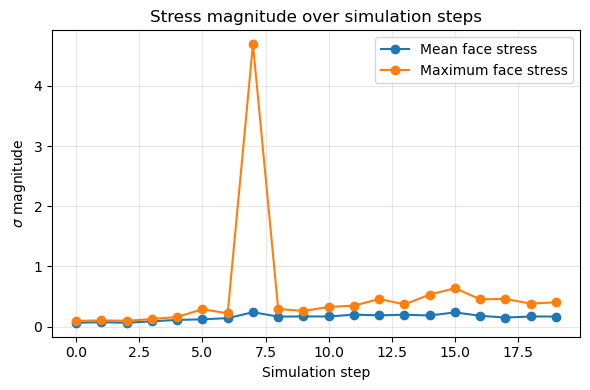

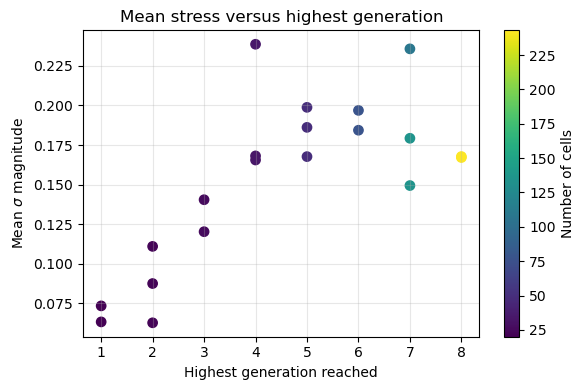

In [39]:
# Stress summaries recorded by the simulation cell above.
# The spatial map is shown during the simulation; these plots summarize it.
data = pd.DataFrame(division_t1_log).copy()

plot_dir = Path.home() / "Tyssue_outputs"
plot_dir.mkdir(parents=True, exist_ok=True)

# fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig1, ax1 = plt.subplots(figsize=(6, 4))

######################################################################################################################
# axes[0].plot(data["step"], data["mean_face_stress"], marker="o", label="Mean face stress")
# axes[0].plot(data["step"], data["max_face_stress"], marker="o", label="Maximum face stress")
# axes[0].set_xlabel("Cell Generation")
# axes[0].set_ylabel(r"$\sigma$ magnitude")
# axes[0].set_title((r"$\sigma$ per cell generation"))
# axes[0].legend()
# axes[0].grid(True, alpha=0.3)

# scatter = axes[1].scatter(
#     data["max_generation"], data["mean_face_stress"],
#     c=data["n_cells"], cmap="viridis", s=45
# )
# axes[1].set_xlabel("No of Cell per Generation")
# axes[1].set_ylabel(r"Mean $\sigma$ magnitude")
# axes[1].set_title("Mean stress by division generation")
# axes[1].grid(True, alpha=0.3)
# fig.colorbar(scatter, ax=axes[1], label="Number of cells")

# plt.tight_layout()
# plt.show()
####################################################################################################################

ax1.plot(data["step"], data["mean_face_stress"],
         marker="o", label="Mean face stress")
ax1.plot(data["step"], data["max_face_stress"],
         marker="o", label="Maximum face stress")

ax1.set_xlabel("Simulation step")
ax1.set_ylabel(r"$\sigma$ magnitude")
ax1.set_title(r"Stress magnitude over simulation steps")
ax1.legend()
ax1.grid(True, alpha=0.3)

fig1.tight_layout()
fig1.savefig(plot_dir / "stress_vs_step.png",
             dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig1)


# Plot 2: mean stress versus highest generation reached
fig2, ax2 = plt.subplots(figsize=(6, 4))

scatter = ax2.scatter(
    data["max_generation"],
    data["mean_face_stress"],
    c=data["n_cells"],
    cmap="viridis",
    s=45
)

ax2.set_xlabel("Highest generation reached")
ax2.set_ylabel(r"Mean $\sigma$ magnitude")
ax2.set_title("Mean stress versus highest generation")
ax2.grid(True, alpha=0.3)

fig2.colorbar(scatter, ax=ax2, label="Number of cells")
fig2.tight_layout()
fig2.savefig(plot_dir / "stress_vs_generation.png",
             dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig2)



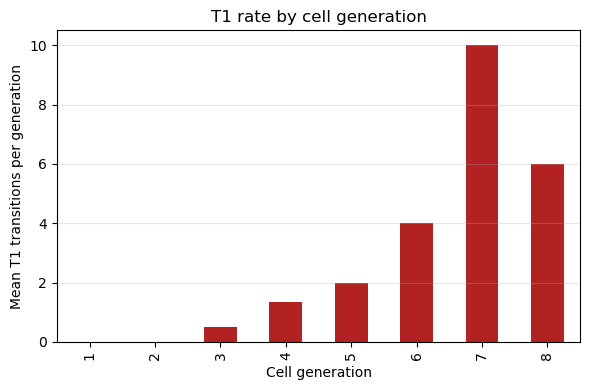

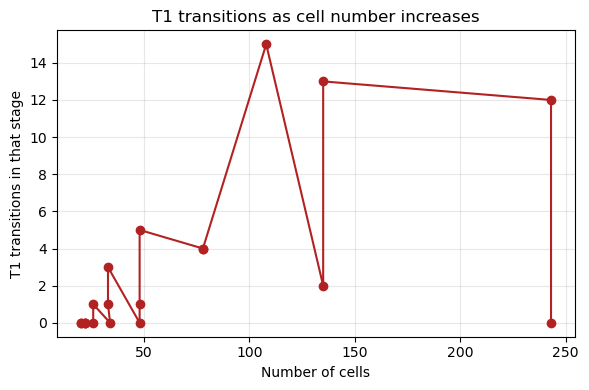

Saved plots to: C:\Users\Aryan\Tyssue_outputs


In [41]:
data = pd.DataFrame(division_t1_log).sort_values("step")

stage_summary = data.groupby("max_generation").agg(
    t1_per_step=("t1_count", "mean"),
    total_t1=("t1_count", "sum"),
    steps=("step", "size"),
    mean_cells=("n_cells", "mean"),
)


save_dir = Path.home() / "Tyssue_outputs"
save_dir.mkdir(parents=True, exist_ok=True)


# Plot 1: mean T1 transitions per step by simulation stage
fig1, ax1 = plt.subplots(figsize=(6, 4))
stage_summary["t1_per_step"].plot(
    kind="bar", ax=ax1, color="firebrick"
)
ax1.set_xlabel("Cell generation")
ax1.set_ylabel("Mean T1 transitions per generation")
ax1.set_title("T1 rate by cell generation")
ax1.grid(axis="y", alpha=0.3)
fig1.tight_layout()
fig1.savefig(save_dir / "t1_rate_by_generation.png",
             dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig1)



# Plot 2: T1 transitions versus cell number
fig2, ax2 = plt.subplots(figsize=(6, 4))
ax2.plot(data["n_cells"], data["t1_count"],
         marker="o", color="firebrick")
ax2.set_xlabel("Number of cells")
ax2.set_ylabel("T1 transitions in that stage")
ax2.set_title("T1 transitions as cell number increases")
ax2.grid(True, alpha=0.3)
fig2.tight_layout()
fig2.savefig(save_dir / "t1_transitions_vs_cell_number.png",
             dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig2)

print(f"Saved plots to: {save_dir}")

In [87]:
print("Total cells:", len(sheet.face_df))

print("\nCells per generation:")
print(sheet.face_df["generation"].value_counts().sort_index())

Total cells: 274

Cells per generation:
0    19
1     8
2    28
3    56
4    70
5    56
6    28
7     8
8     1
Name: generation, dtype: int64


In [89]:
print(sheet.face_df[["area", "num_sides"]])

          area  num_sides
face                     
0     3.536742          6
1     3.471614          6
2     3.779940          8
3     3.575382          4
4     3.657387          6
...        ...        ...
269   3.421957          6
270   3.470780          5
271   3.651924          8
272   3.434724          6
273   3.444127          6

[274 rows x 2 columns]


In [ ]:
from tyssue import History

t = 0
stop = 30

# The History object records all the time steps 
history = History(sheet)

while manager.current and t < stop:
    # Execute the event in the current list
    manager.execute(sheet)
    t += 1
    sheet.reset_index(order=False)
    # Find energy min
    res = solver.find_energy_min(sheet, geom, area_model)

    
    history.record()
    # Switch event list from the next list to the current list
    manager.update()

In [ ]:
draw_specs = {
    "edge": {
        "color": lambda sheet: sheet.edge_df.length
    },
    "face": {
        "visible": True,
        "color": lambda sheet: sheet.face_df.area,
        "color_range": (0, 10),
        "colormap": "Blues"
    }
}




create_gif(history, "growth.gif", num_frames=100, margin=5, **draw_specs)

In [ ]:
from tyssue.topology.sheet_topology import cell_division

def division(sheet, manager, cell_id=0, crit_area=4.0, growth_rate=0.1, dt=1.):
    """Defines a division behavior.
    
    Parameters
    ----------
    
    sheet: a :class:`Sheet` object
    cell_id: int
        the index of the dividing cell
    crit_area: float
        the area at which 
    growth_rate: float
        increase in the prefered are per unit time
        A_0(t + dt) = A0(t) * (1 + growth_rate * dt)
    """

    
    if sheet.face_df.loc[cell_id, "area"] > crit_area:
        # restore prefered_area
        sheet.face_df.loc[0, "prefered_area"] = 1.0
        # Do division
        daughter = cell_division(sheet, cell_id, geom)
        # Update the topology
        sheet.reset_index(order=True)
        # update geometry
        geom.update_all(sheet)
        print(f"cell n°{daughter} is born")
    else:
        # 
        sheet.face_df.loc[0, "prefered_area"] *= (1 + dt * growth_rate)
        manager.append(division, cell_id=cell_id)

In [ ]:
from tyssue.behaviors import EventManager

# Initialisation of manager 
manager = EventManager("face")

# Add action/event to the manager
manager.append(division, cell_id=0)

In [ ]:
print('manager.current :')
print(manager.current)
print()
print('manager.next :')
print(manager.next)

In [ ]:
from tyssue import History

t = 0
stop = 30

# The History object records all the time steps 
history = History(sheet)

while manager.current and t < stop:
    # Execute the event in the current list
    manager.execute(sheet)
    t += 1
    sheet.reset_index(order=False)
    # Find energy min
    res = solver.find_energy_min(sheet, geom, area_model)

    
    history.record()
    # Switch event list from the next list to the current list
    manager.update()

In [ ]:
for i, (time, saved_sheet) in enumerate(history):

    print(
        f"Frame {i} | "
        f"coords = {saved_sheet.coords} | "
        f"rx = {'rx' in saved_sheet.edge_df.columns} | "
        f"ry = {'ry' in saved_sheet.edge_df.columns} | "
        f"rz = {'rz' in saved_sheet.edge_df.columns}"
    )

In [ ]:
draw_specs = {
    "edge": {
        "color": lambda sheet: sheet.edge_df.length
    },
    "face": {
        "visible": True,
        "color": lambda sheet: sheet.face_df.area,
        "color_range": (0, 10),
        "colormap": "Blues"
    }
}




create_gif(history, "growth.gif", num_frames=100, margin=5, **draw_specs)
# display.Image("growth.gif")

In [ ]:
face_id = 0

edges = sheet.edge_df[
    sheet.edge_df["face"] == face_id
]

print(edges[["srce", "trgt"]])

vertex_ids = edges["srce"].to_numpy()

print("\nVertex coordinates:")

print(
    sheet.vert_df.loc[
        vertex_ids,
        ["x", "y", "z"]
    ]
)